linear 0.9824561403508771
rbf 0.9766081871345029
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        64
           1       0.98      0.98      0.98       107

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



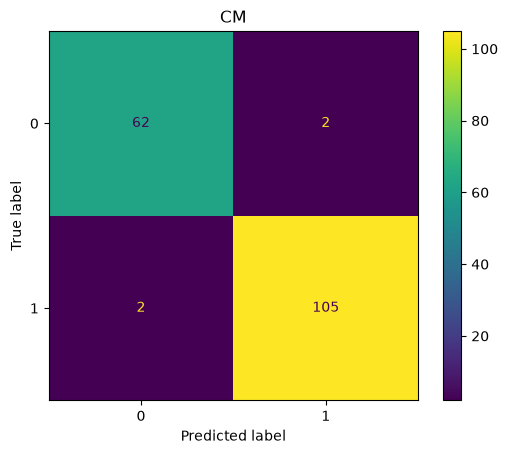

In [1]:
# ===================== REVISION / ONE-SHOT: SVM =====================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 1) Load (CSV: df = pd.read_csv("datasets/Social_Network_Ads (2).csv"); X = df[["Age", "EstimatedSalary"]])
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 2) ALWAYS scale for SVM (fit on train only)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# 3) Linear vs RBF
for k in ["linear", "rbf"]:
    model = SVC(kernel=k, C=1, gamma="scale", random_state=42).fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(k, accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred); plt.title("CM"); plt.show()

# 4) Tuning with pipeline + grid search (param names: step__param)
pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])
grid = GridSearchCV(pipe, {"svc__kernel": ["linear", "rbf", "poly"], "svc__C": [0.1, 1, 10]}, cv=5)

# 5) Decision boundary (only for 2 features)
# DecisionBoundaryDisplay.from_estimator(model2d, X2d, alpha=0.3); plt.scatter(X2d[:, 0], X2d[:, 1], c=y2d)

# ---------------- VIVA NOTES ----------------
# SVM finds the hyperplane with maximum margin; points on the margin are support vectors.
# C: high C = hard margin (fits train tightly, may overfit); low C = soft margin (more errors allowed).
# gamma (RBF): high = very curvy boundary (overfit), low = smooth boundary.
# Kernels: linear, rbf (default), poly, sigmoid; kernel trick maps data to higher dimensions.
# Scaling is a must because SVM depends on distances / dot products.
# Read boundary plot: coloured regions = predicted class, points = true class.

### Q41

Consider Social_Netwok_Ads.csv dataset - (UserID, Gender, Age, EstimatedSalary, Purchased). Use Age and EstimatedSalary as input features and Purchased as target feature. Split test data set 30% of complete dataset. Build two models of support vector classifier in python using sklearn library, one for linear and another for RBF kernel with C and gamma parameters set. Predict test labels and print test accuracy.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score

In [3]:
# Real file name in the datasets folder is "Social_Network_Ads (2).csv"
df = pd.read_csv("datasets/Social_Network_Ads (2).csv")
print(df.head())
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0


In [4]:
# 30% test split, then scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [5]:
# Model 1: linear kernel
model_lin = SVC(kernel="linear", C=1.0, random_state=42)
model_lin.fit(X_train, y_train)
y_pred = model_lin.predict(X_test)
print("Linear SVC test accuracy:", accuracy_score(y_test, y_pred))

# Model 2: RBF kernel with C and gamma set
model_rbf = SVC(kernel="rbf", C=10, gamma=0.5, random_state=42)
model_rbf.fit(X_train, y_train)
y_pred = model_rbf.predict(X_test)
print("RBF SVC test accuracy:   ", accuracy_score(y_test, y_pred))

Linear SVC test accuracy: 0.85
RBF SVC test accuracy:    0.95


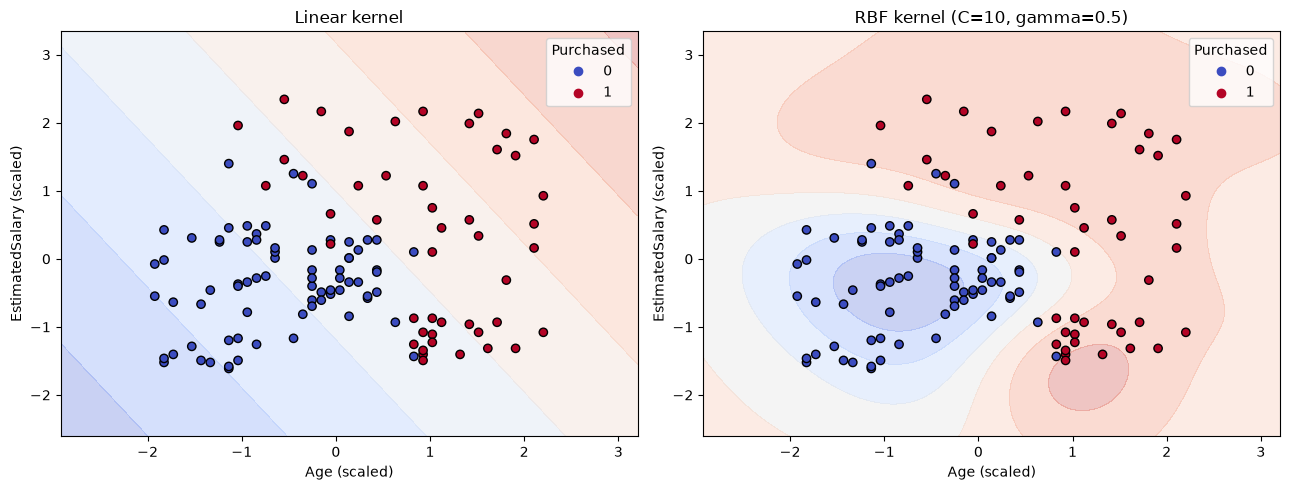

In [6]:
# Decision boundaries on test data
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, m, title in [(ax[0], model_lin, "Linear kernel"), (ax[1], model_rbf, "RBF kernel (C=10, gamma=0.5)")]:
    DecisionBoundaryDisplay.from_estimator(m, X_test, alpha=0.3, cmap="coolwarm", ax=a)
    sc_ = a.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", edgecolor="k")
    a.legend(*sc_.legend_elements(), title="Purchased")
    a.set_title(title)
    a.set_xlabel("Age (scaled)")
    a.set_ylabel("EstimatedSalary (scaled)")
plt.tight_layout()
plt.show()

### Q42

Develop a Support Vector Classifier to predict whether a tumor is malignant or benign based on 30 features computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. The dataset contains 569 samples with binary labels indicating tumor type. (breast_cancer dataset of sklearn) Load the Dataset from sklearn.Split the dataset into training and testing sets.Train the SVC Model using the training data. Visualize the Results.

In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

In [8]:
# Load and split
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target                      # 0 = malignant, 1 = benign
print("X shape:", X.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X shape: (569, 30)


In [9]:
# Scale and train SVC
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
model = SVC(kernel="rbf", C=1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Accuracy: 0.9824561403508771
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



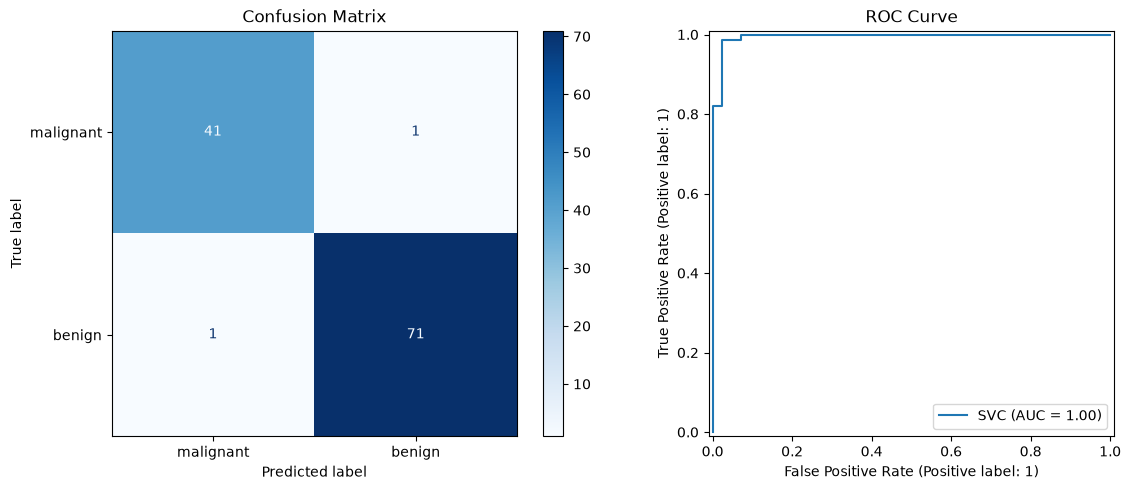

In [10]:
# Visual 1: confusion matrix, Visual 2: ROC curve
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=cancer.target_names, cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion Matrix")
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax[1])
ax[1].set_title("ROC Curve")
plt.tight_layout()
plt.show()

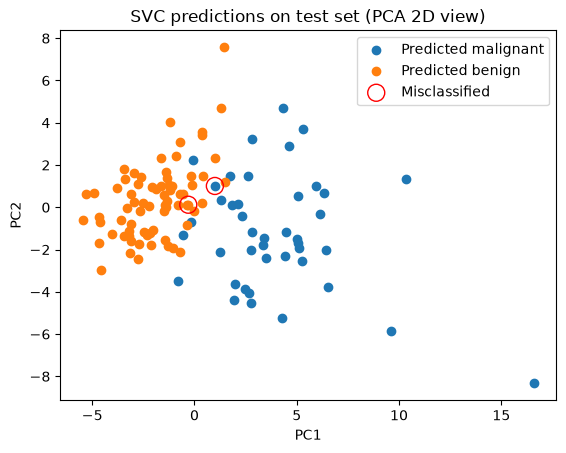

In [11]:
# Visual 3: test points in 2D (PCA), coloured by prediction, wrong ones circled
X_test_2d = PCA(n_components=2).fit(X_train).transform(X_test)
for c, name in enumerate(cancer.target_names):
    plt.scatter(X_test_2d[y_pred == c, 0], X_test_2d[y_pred == c, 1], label=f"Predicted {name}")
wrong = y_pred != y_test
plt.scatter(X_test_2d[wrong, 0], X_test_2d[wrong, 1], facecolors="none", edgecolors="red", s=150, label="Misclassified")
plt.title("SVC predictions on test set (PCA 2D view)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

### Q43

Write a Python program to implement SVM classification for breast cancerprediction with the following requirements: Data preprocessing using StandardScaler use kernel parameters for tuning.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [13]:
# Load and split
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
# Pipeline: StandardScaler -> SVC, tune kernel parameters with 5-fold grid search
pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])
params = {
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1],
}
grid = GridSearchCV(pipe, params, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Best parameters: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best CV accuracy: 0.9802


Test accuracy: 0.9824561403508771
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



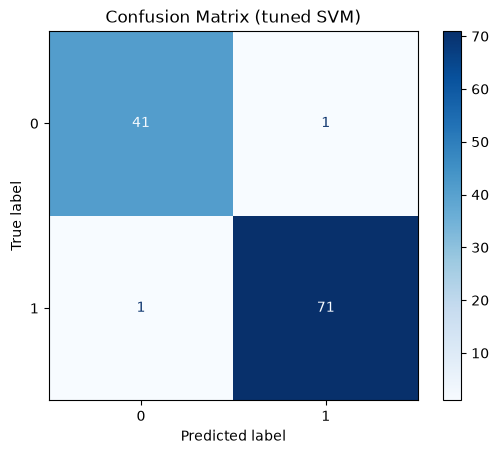

In [15]:
# Evaluate best model on test set
model = grid.best_estimator_
y_pred = model.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix (tuned SVM)")
plt.show()

param_svc__kernel
linear    0.978022
poly      0.969231
rbf       0.980220
Name: mean_test_score, dtype: float64


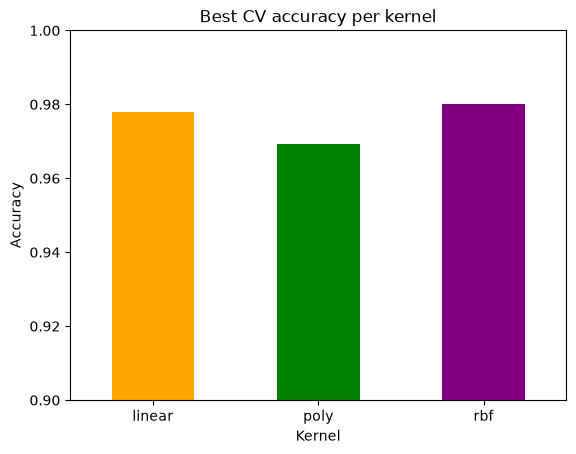

In [16]:
# Compare kernels: best CV score per kernel
res = pd.DataFrame(grid.cv_results_)
best_per_kernel = res.groupby("param_svc__kernel")["mean_test_score"].max()
print(best_per_kernel)
best_per_kernel.plot(kind="bar", color=["orange", "green", "purple"])
plt.title("Best CV accuracy per kernel")
plt.xlabel("Kernel")
plt.ylabel("Accuracy")
plt.ylim(0.9, 1)
plt.xticks(rotation=0)
plt.show()

### Q70

Implement an SVC model to classify iris flowers into three species (Setosa, Versicolor, and Virginica) based on their sepal and petal dimensions. The dataset contains 150 samples with four features: sepal length, sepal width, petal length, and petal width. Load the Dataset from sklearn.Split the dataset into training and testing sets.Train the SVC Model using the training data. Visualize the Results.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [18]:
# Load and split
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [19]:
# Train SVC on all 4 features
model = SVC(kernel="rbf", C=1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



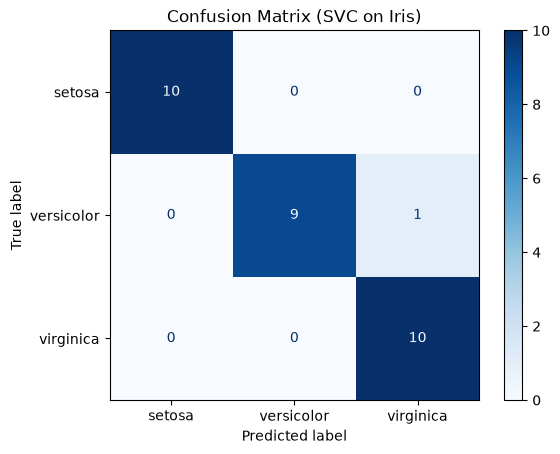

In [20]:
# Visual 1: confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=iris.target_names, cmap="Blues")
plt.title("Confusion Matrix (SVC on Iris)")
plt.show()

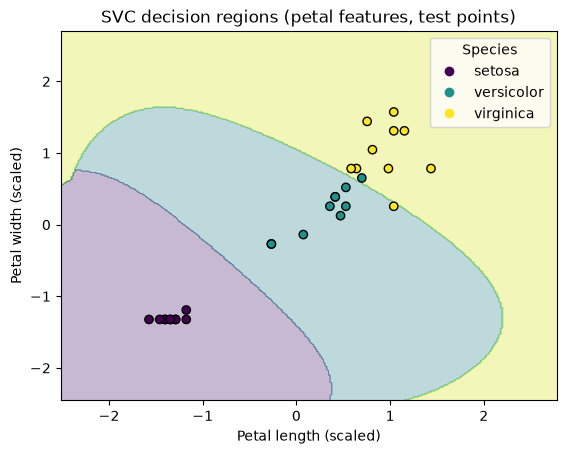

In [21]:
# Visual 2: decision regions using only petal length and petal width (2 features can be drawn)
X2_train, X2_test = X_train[:, 2:4], X_test[:, 2:4]
model2 = SVC(kernel="rbf", C=1, random_state=42).fit(X2_train, y_train)
# grid of points covering the plot, predict class of every grid point
xx, yy = np.meshgrid(np.linspace(X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1, 300),
                     np.linspace(X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1, 300))
Z = model2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
sc_ = plt.scatter(X2_test[:, 0], X2_test[:, 1], c=y_test, cmap="viridis", edgecolor="k")
plt.legend(sc_.legend_elements()[0], iris.target_names, title="Species")
plt.title("SVC decision regions (petal features, test points)")
plt.xlabel("Petal length (scaled)")
plt.ylabel("Petal width (scaled)")
plt.show()